In [2]:
import yfinance
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.dates import ConciseDateFormatter
import numpy as np
import math

#### Cloture ajusté => Ici on prend en compte les dividendes de fin d'année si le SPY passe de 100 dollars a 99 dollars, y'aura une baisse de 1% mais en réalité c'est juste une distribution des dividendes et genre toi si tu avais des actions tu auras 99$ d'actions et 1$ de dividendes


In [3]:
SPY = yfinance.download("SPY", start="2015-01-01",interval='1d',auto_adjust= True) #ici le auto adjust est bien pour la cloture ajusté 

print("\n \n Verifier qualité index et manipulations \n\n")
print(SPY.index.is_monotonic_increasing)
print(SPY.index.has_duplicates)
print(SPY.columns)
print(SPY['Close'].isna().sum())

[*********************100%***********************]  1 of 1 completed


 
 Verifier qualité index et manipulations 


True
False
MultiIndex([( 'Close', 'SPY'),
            (  'High', 'SPY'),
            (   'Low', 'SPY'),
            (  'Open', 'SPY'),
            ('Volume', 'SPY')],
           names=['Price', 'Ticker'])
Ticker
SPY    0
dtype: int64


In [4]:
SPY_2026=SPY.loc['2026-01-01':]

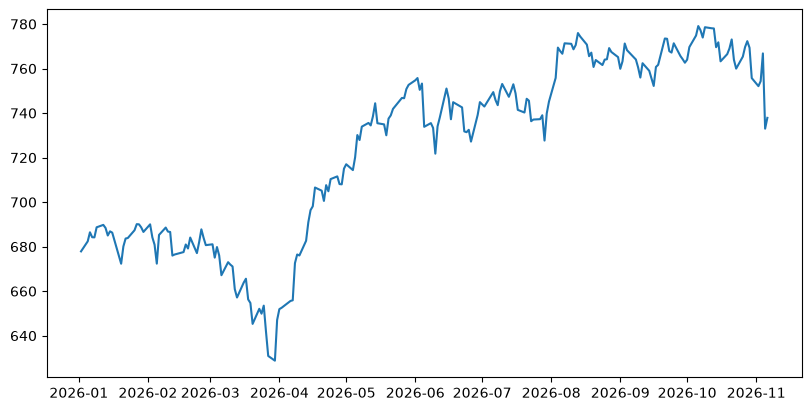

In [ ]:
fig, ax=plt.subplots(figsize=(8,4), layout='constrained')
ax.plot(SPY_2026.index,SPY_2026['Close'])

### Rendements

In [6]:
# Rendements simple c'est ni plus ni moins que l'évolution sur base 100 par rapport a la veille donc soit positif / négatif ou neutre 

rendements = (SPY["Close"] / SPY['Close'].shift(1))-1
print(rendements)

rendements_test = SPY['Close'].pct_change()
print(f"\n\n {rendements_test}")

Ticker           SPY
Date                
2015-01-02       NaN
2015-01-05 -0.018060
2015-01-06 -0.009419
2015-01-07  0.012461
2015-01-08  0.017745
...              ...
2026-11-02 -0.004790
2026-11-03  0.002992
2026-11-04  0.016518
2026-11-05 -0.044092
2026-11-06  0.006630

[2980 rows x 1 columns]


 Ticker           SPY
Date                
2015-01-02       NaN
2015-01-05 -0.018060
2015-01-06 -0.009419
2015-01-07  0.012461
2015-01-08  0.017745
...              ...
2026-11-02 -0.004790
2026-11-03  0.002992
2026-11-04  0.016518
2026-11-05 -0.044092
2026-11-06  0.006630

[2980 rows x 1 columns]


In [7]:
# Rendements logarithmique => Permet d'aditionner les rendements des séances pour mesurer l'évolution
rendements_log = np.log1p(rendements_test)
print(rendements_log)

Ticker           SPY
Date                
2015-01-02       NaN
2015-01-05 -0.018225
2015-01-06 -0.009463
2015-01-07  0.012384
2015-01-08  0.017589
...              ...
2026-11-02 -0.004802
2026-11-03  0.002987
2026-11-04  0.016383
2026-11-05 -0.045093
2026-11-06  0.006608

[2980 rows x 1 columns]


In [8]:
rendements.describe()

"""
Ici describe donne les stats de base sur les rendements on voit que depuis donc 2015 en moyenne chaque séance fait 0,055%
 1 quart des séances et soit en dessous ou égal du seuil de -0,33% , la moitié a fait au moins 0,06% et 1 quart a fait 0,5 ou plus
"""

'\nIci describe donne les stats de base sur les rendements on voit que depuis donc 2015 en moyenne chaque séance fait 0,055%\n 1 quart des séances et soit en dessous ou égal du seuil de -0,33% , la moitié a fait au moins 0,06% et 1 quart a fait 0,5 ou plus\n'

# Affichage 

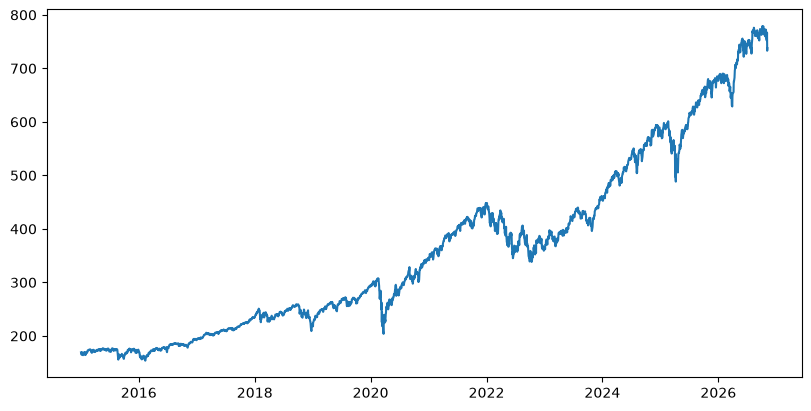

In [9]:
fig, ax=plt.subplots(figsize=(8,4), layout='constrained')
ax.plot(SPY.index,SPY['Close'])

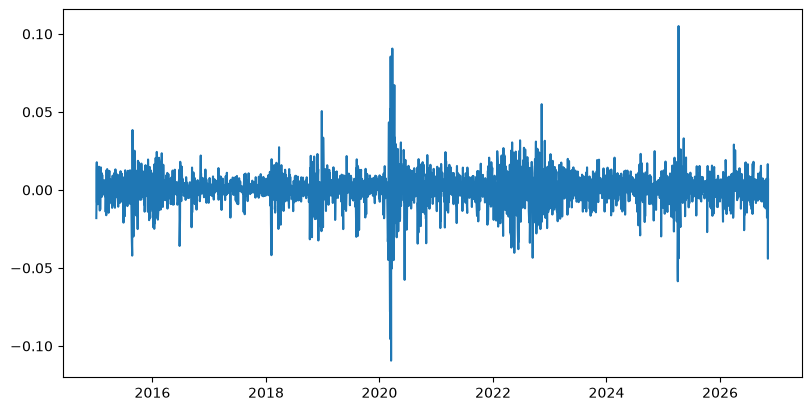

In [10]:
fig, ax=plt.subplots(figsize=(8,4), layout='constrained')
ax.plot(rendements)

(array([  1.,   0.,   0.,   1.,   0.,   0.,   0.,   0.,   1.,   0.,   0.,
          0.,   0.,   0.,   2.,   0.,   3.,   0.,   8.,   2.,   5.,   8.,
         17.,  22.,  27.,  53.,  82., 113., 220., 388., 660., 518., 346.,
        227., 132.,  63.,  28.,  23.,   8.,   8.,   1.,   1.,   2.,   0.,
          1.,   3.,   1.,   0.,   0.,   1.,   0.,   0.,   0.,   0.,   1.,
          1.,   0.,   0.,   0.,   1.]),
 array([-10.94240005, -10.58499457, -10.22758909,  -9.87018361,
         -9.51277812,  -9.15537264,  -8.79796716,  -8.44056168,
         -8.08315619,  -7.72575071,  -7.36834523,  -7.01093975,
         -6.65353426,  -6.29612878,  -5.9387233 ,  -5.58131782,
         -5.22391233,  -4.86650685,  -4.50910137,  -4.15169589,
         -3.7942904 ,  -3.43688492,  -3.07947944,  -2.72207396,
         -2.36466847,  -2.00726299,  -1.64985751,  -1.29245203,
         -0.93504654,  -0.57764106,  -0.22023558,   0.1371699 ,
          0.49457539,   0.85198087,   1.20938635,   1.56679183,
          1.92

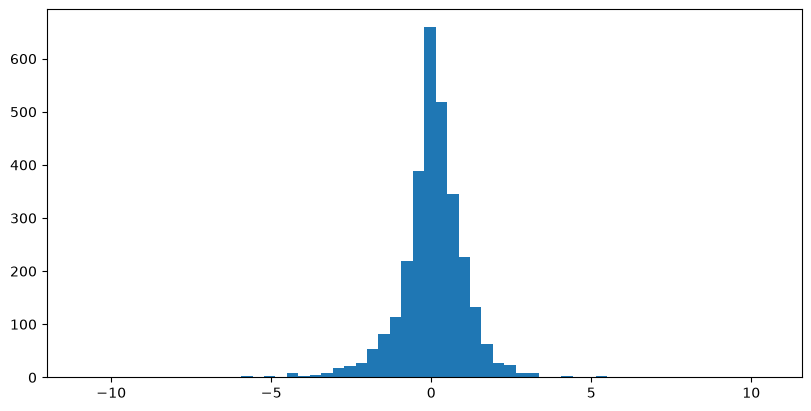

In [11]:
rendements_clean = rendements.dropna() * 100
fig, ax=plt.subplots(figsize=(8,4), layout='constrained')
ax.hist(rendements_clean,bins=60)

### Volatilité glissante sur 21 séances

$$
\sigma = \sqrt{\frac{\sum_{i=1}^{21}(r_i-\bar{r})^2}{21-1}}
$$

- $r_i$ est le rendement de la séance $i$.
- $\bar{r}$ est la moyenne des 21 rendements de la fenêtre.
- $\sigma$ est la volatilité journalière estimée sur ces 21 séances.

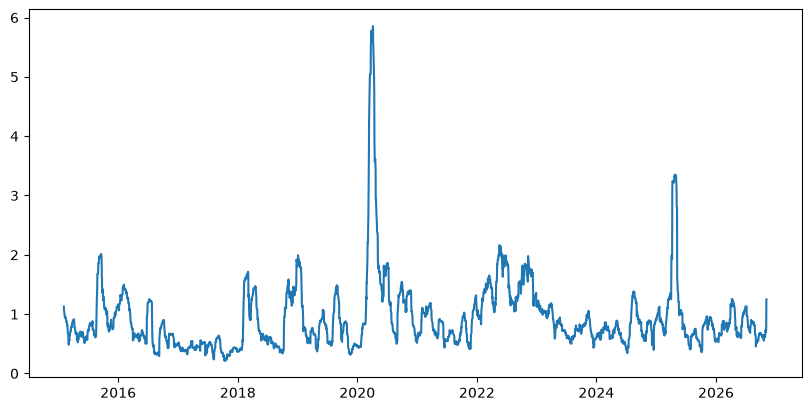

In [12]:
volatilite_rendements = rendements_clean.rolling(21).std()
fig, ax=plt.subplots(figsize=(8,4), layout='constrained')
ax.plot(volatilite_rendements)

# Ca ressemble au VIX => Mais le VIX utilise la volatilite implicite 

##### Objectif maintenant c'est de mesurer le drawdown de SPY

In [23]:
capital_init =  100
rendements_multiplicateur = rendements.dropna() + 1
temp = rendements_multiplicateur.cumprod() # cumprod cette fonction permet juste de multiplier la valeur précédente par la nouvelle etc et ca cumule
capital_final = capital_init*temp.iloc[-1, 0]
print(f"Si en 2015 j'avais mis 100 euros aujourd'hui en 2026 j'aurais eu {capital_final}")

Si en 2015 j'avais mis 100 euros aujourd'hui en 2026 j'aurais eu 435.9134767982711


In [34]:
# Ici on va calculer l'évolution de ce drawdown sur la période et en faire un graphe pour voir les période ou on a les plus gros drawdown
# Pour rappel le drawdown c'est le capital du moment T que l'on dive par le plus haut atteint jusque la et en enleve 1 pour avoir une valeur entre 0 et 1

capital_seance = 100 * temp
sommet_cumule = capital_seance.cummax()
drawdown = 100 - ((capital_seance/sommet_cumule)*100)


Text(0.5, 0, 'Date')

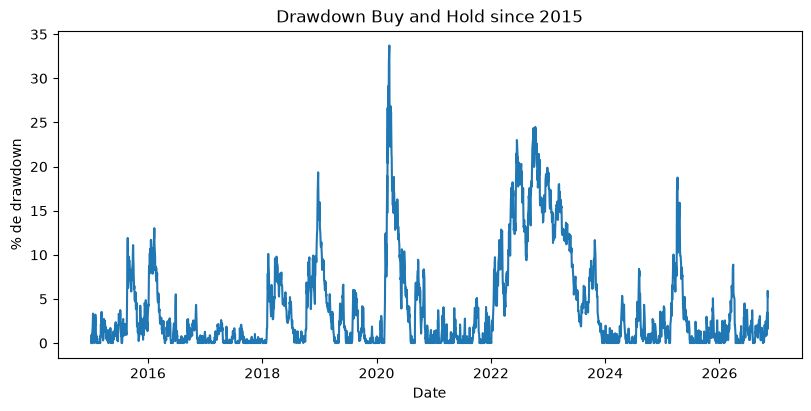

In [39]:
fig, ax=plt.subplots(figsize=(8,4), layout='constrained')
ax.plot(drawdown)
ax.set_title("Drawdown Buy and Hold since 2015")
ax.set_ylabel("% de drawdown")
ax.set_xlabel("Date")

Text(0.5, 0, 'Date')

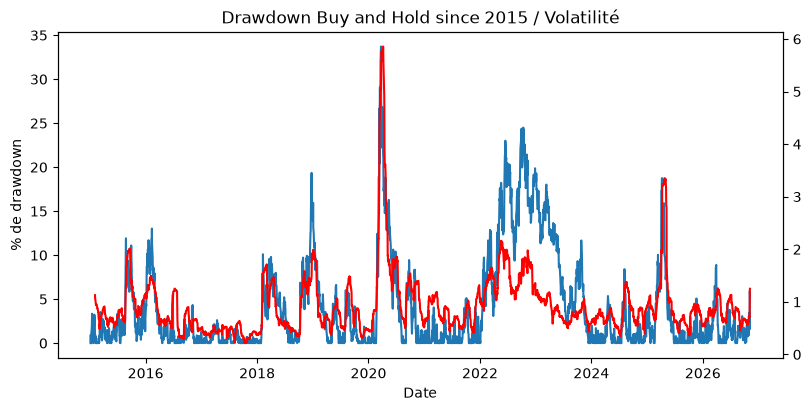

In [43]:
fig, ax=plt.subplots(figsize=(8,4), layout='constrained')
ax.plot(drawdown)
ax_vol = ax.twinx()
ax_vol.plot(volatilite_rendements, color='red')
ax.set_title("Drawdown Buy and Hold since 2015 / Volatilité")
ax.set_ylabel("% de drawdown")
ax.set_xlabel("Date")

In [47]:
# Corélation de Pearson pour voir la corélation entre drawdown et volatilité
correlation = drawdown["SPY"].corr(volatilite_rendements["SPY"])
print(f"Correlation entre drawdown et volat {correlation}")

Correlation entre drawdown et volat 0.7132812526110124
